# Tugas 2 — Scatter Plot dengan Matplotlib

**Nama : Yogi Ardiansyah**

**NIM  : 231101063**

**Kelas : TI 7 B**

**Mata Kuliah:** Visualisasi Data  
**Sumber materi:** Modul VD 1–4, Bab 2.2 *Scatter Plot*  
**Tools:** Python, NumPy, Pandas, Matplotlib

Notebook ini mengerjakan subbab yang ditugaskan: **2.2.1, 2.2.2.1, 2.2.2.2, 2.2.3, 2.2.3.1, dan 2.2.3.3**. Data yang digunakan merupakan **data sintetis (data buatan)** seperti pada modul, bukan data dari sumber eksternal.


## 1. Persiapan Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Mengatur tampilan grafik agar ukuran dan label mudah dibaca
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print('Library berhasil diimpor.')

Library berhasil diimpor.


## 2.2.1. Membuat Scatter Plot dengan Matplotlib

Bagian ini membuat data sintetis untuk **usia** dan **penghasilan** 100 orang, kemudian menampilkan hubungan kedua variabel tersebut dalam scatter plot.

Lima baris pertama data usia dan penghasilan:


,Usia,Penghasilan
0,58,28466.803636
1,48,22768.850074
2,34,20539.149034
3,27,10805.376182
4,40,22504.386258


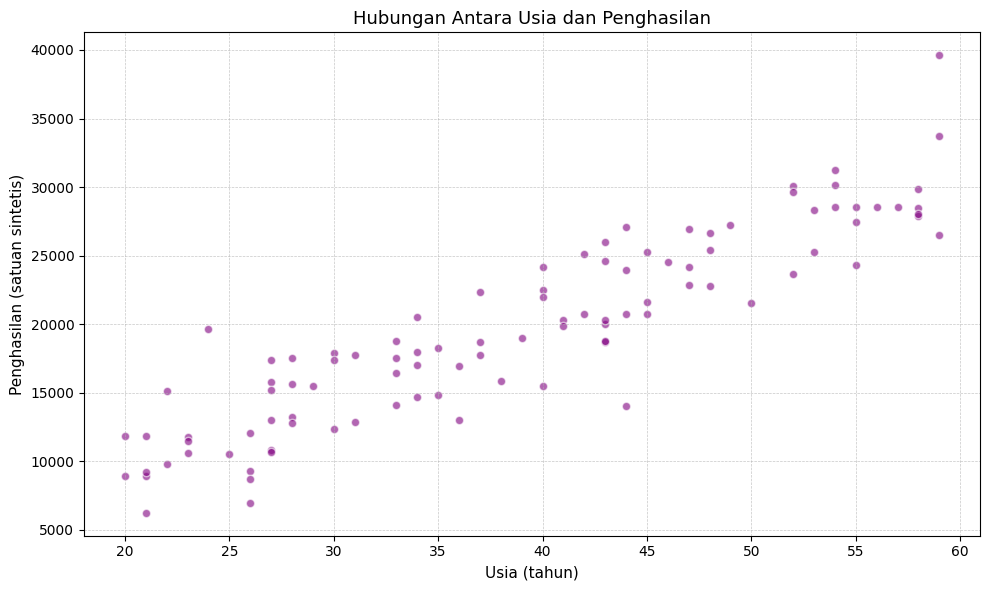

In [2]:
# Membuat data sintetis untuk usia dan penghasilan
np.random.seed(42)  # Menentukan seed agar hasil dapat direproduksi
usia = np.random.randint(20, 60, 100)
penghasilan = (usia * 500) + np.random.randn(100) * 3000

df_usia_penghasilan = pd.DataFrame({
    'Usia': usia,
    'Penghasilan': penghasilan
})

print('Lima baris pertama data usia dan penghasilan:')
display(df_usia_penghasilan.head())

# Membuat scatter plot dasar
plt.figure(figsize=(10, 6))
plt.scatter(
    df_usia_penghasilan['Usia'],
    df_usia_penghasilan['Penghasilan'],
    color='purple', alpha=0.6, edgecolors='white'
)
plt.title('Hubungan Antara Usia dan Penghasilan')
plt.xlabel('Usia (tahun)')
plt.ylabel('Penghasilan (satuan sintetis)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

**Interpretasi:** Grafik digunakan untuk melihat hubungan antara usia dan penghasilan. Data sintetis ini dirancang dengan kecenderungan penghasilan meningkat seiring bertambahnya usia, meskipun ada variasi acak pada setiap titik.

## 2.2.2.1. Mengubah Ukuran Titik

Ukuran titik dibuat berdasarkan penghasilan. Titik yang lebih besar menandakan nilai penghasilan yang lebih tinggi.

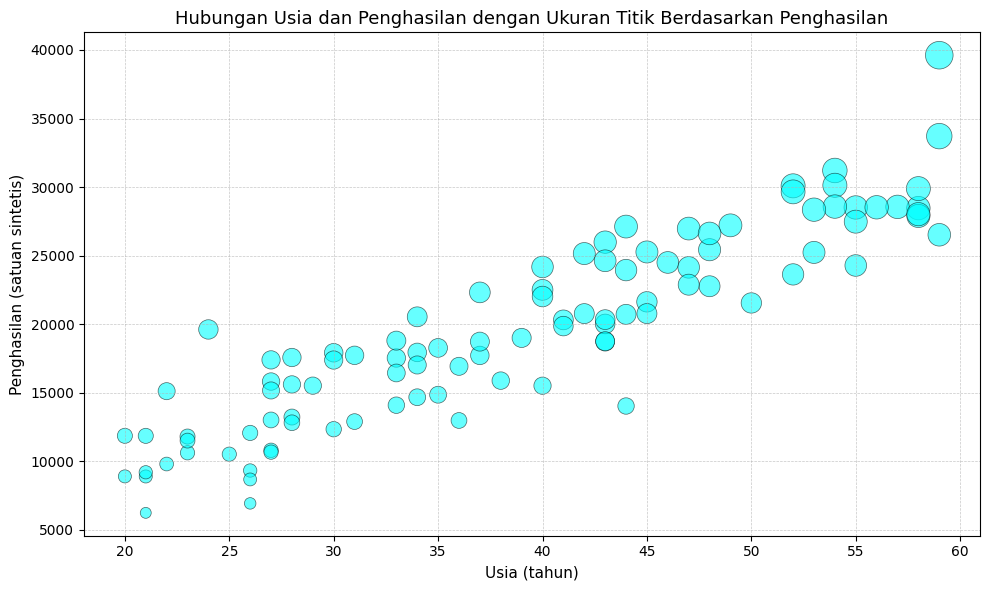

In [3]:
# Menggunakan penghasilan untuk menentukan ukuran titik
sizes = df_usia_penghasilan['Penghasilan'] / 100

plt.figure(figsize=(10, 6))
plt.scatter(
    df_usia_penghasilan['Usia'],
    df_usia_penghasilan['Penghasilan'],
    color='cyan', alpha=0.6, s=sizes,
    edgecolors='black', linewidth=0.5
)
plt.title('Hubungan Usia dan Penghasilan dengan Ukuran Titik Berdasarkan Penghasilan')
plt.xlabel('Usia (tahun)')
plt.ylabel('Penghasilan (satuan sintetis)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

**Interpretasi:** Selain posisi titik, ukuran titik memberikan informasi tambahan. Titik yang lebih besar menunjukkan penghasilan yang relatif lebih tinggi.

## 2.2.2.2. Menggunakan Warna untuk Menunjukkan Kategori Lain

Bagian ini menambahkan kategori **jenis kelamin** dan menggunakan warna yang berbeda agar kedua kategori dapat dibedakan pada scatter plot.

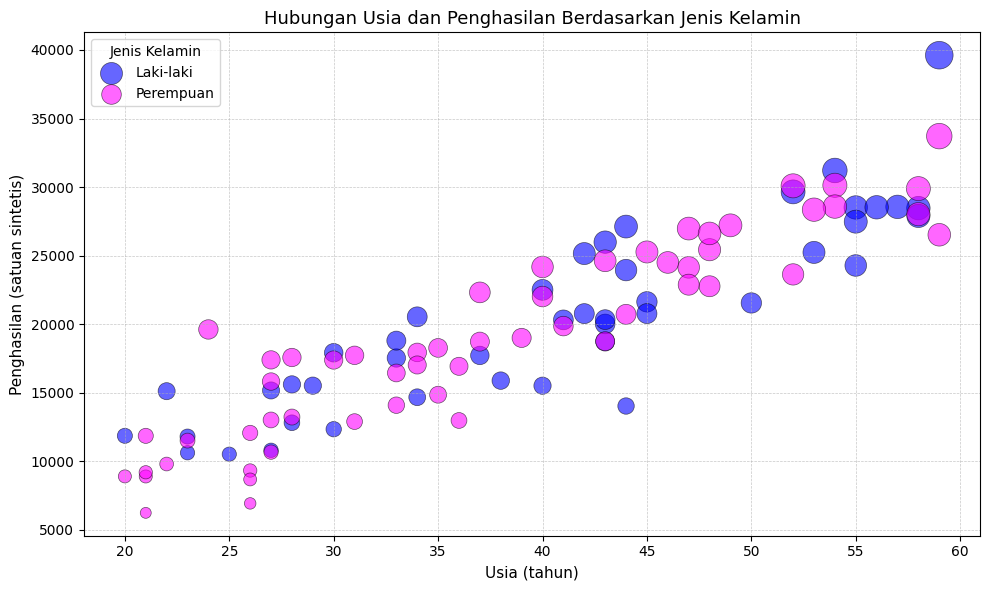

Jumlah data per kategori:


,Jumlah
Jenis Kelamin,
Perempuan,56
Laki-laki,44


In [4]:
# Menambahkan data sintetis untuk jenis kelamin
np.random.seed(42)
jenis_kelamin = np.random.choice(['Laki-laki', 'Perempuan'], 100)
df_usia_penghasilan['Jenis Kelamin'] = jenis_kelamin

# Pemetaan warna untuk setiap kategori
warna_gender = {
    'Laki-laki': 'blue',
    'Perempuan': 'magenta'
}

plt.figure(figsize=(10, 6))
for kategori, warna in warna_gender.items():
    mask = df_usia_penghasilan['Jenis Kelamin'] == kategori
    plt.scatter(
        df_usia_penghasilan.loc[mask, 'Usia'],
        df_usia_penghasilan.loc[mask, 'Penghasilan'],
        color=warna,
        alpha=0.6,
        s=sizes.loc[mask],
        edgecolors='black',
        linewidth=0.5,
        label=kategori
    )

plt.title('Hubungan Usia dan Penghasilan Berdasarkan Jenis Kelamin')
plt.xlabel('Usia (tahun)')
plt.ylabel('Penghasilan (satuan sintetis)')
plt.legend(title='Jenis Kelamin')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

print('Jumlah data per kategori:')
display(df_usia_penghasilan['Jenis Kelamin'].value_counts().rename_axis('Jenis Kelamin').to_frame('Jumlah'))

**Interpretasi:** Warna biru mewakili kategori laki-laki dan magenta mewakili kategori perempuan. Warna membantu membandingkan distribusi kedua kategori, sementara posisi titik menunjukkan usia dan penghasilan.

## 2.2.3. Kasus: Performa Iklan Online

Pada studi kasus ini, data sintetis menggambarkan **jumlah klik** pada iklan dan **jumlah konversi** (misalnya pembelian setelah iklan diklik). Bagian ini membuat dataset yang akan dipakai pada grafik berikutnya.

In [5]:
# Membuat data sintetis untuk klik dan konversi
np.random.seed(45)  # Seed untuk konsistensi hasil
klik = np.random.randint(100, 1000, 50)
konversi = klik * 0.1 + np.random.randn(50) * 30  # Ditambah variasi acak (noise)

df_iklan = pd.DataFrame({
    'Klik': klik,
    'Konversi': konversi
})

print('Lima baris pertama data iklan:')
display(df_iklan.head())
print(f'Jumlah baris data iklan: {len(df_iklan)}')

Lima baris pertama data iklan:


,Klik,Konversi
0,514,73.426021
1,743,44.938169
2,992,106.222797
3,644,37.322692
4,707,105.306320


Jumlah baris data iklan: 50


## 2.2.3.1. Membuat Scatter Plot Dasar

Scatter plot digunakan untuk melihat hubungan antara jumlah klik dan konversi.

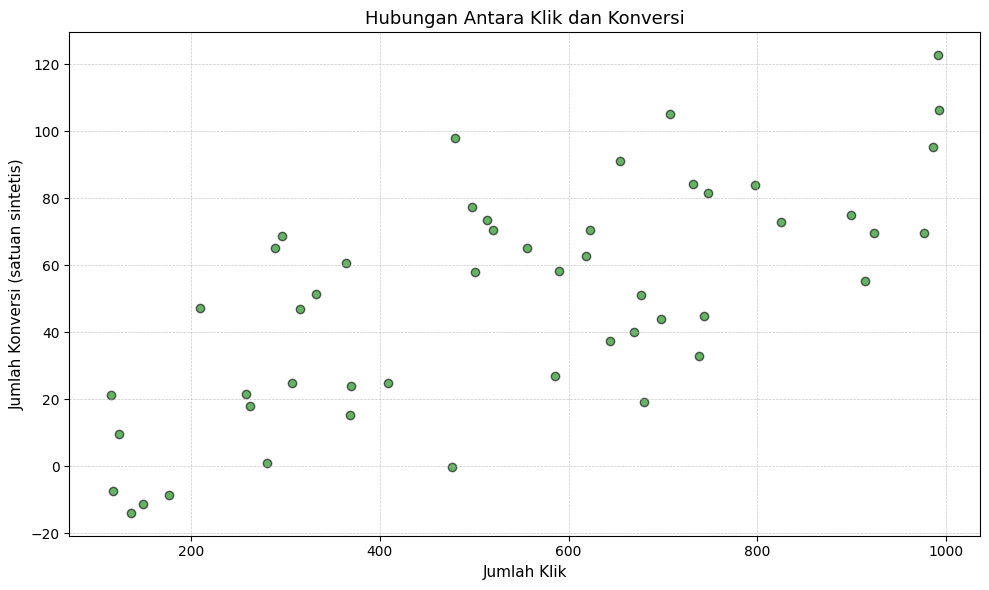

In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df_iklan['Klik'],
    df_iklan['Konversi'],
    color='green', alpha=0.6, edgecolors='black'
)
plt.title('Hubungan Antara Klik dan Konversi')
plt.xlabel('Jumlah Klik')
plt.ylabel('Jumlah Konversi (satuan sintetis)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

**Interpretasi:** Scatter plot menunjukkan sebaran hubungan antara jumlah klik dan konversi pada data sintetis. Variasi titik muncul karena nilai konversi diberi komponen acak, sehingga hubungan yang terlihat tidak selalu tepat pada satu garis.

## 2.2.3.3. Menggunakan Warna berdasarkan Durasi Iklan

Bagian ini menggunakan warna titik untuk menunjukkan durasi kampanye iklan dalam hari. Pada contoh modul, ukuran titik juga menggunakan variabel `Biaya` yang diperkenalkan di subbab 2.2.3.2. Karena subbab 2.2.3.2 tidak termasuk daftar tugas, variabel biaya dan ukuran titik disiapkan di bawah ini sebagai **prasyarat kode saja**, tanpa membuat grafik terpisah.

Agar ukuran titik valid, nilai biaya sintetis dibatasi minimal 1.

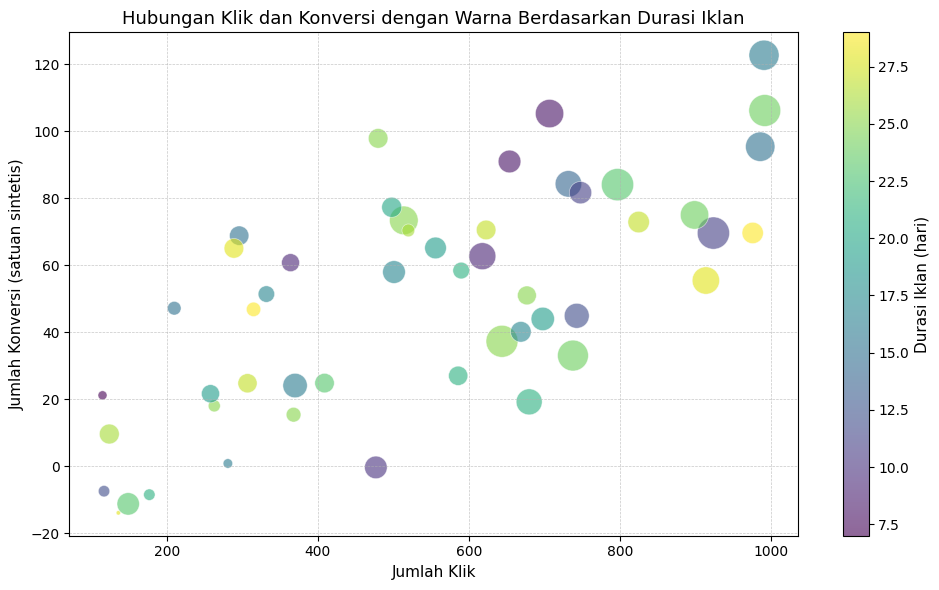

Ringkasan data iklan setelah penambahan biaya dan durasi:


,Klik,Konversi,Biaya,Durasi
0,514,73.426021,42.457491,25
1,743,44.938169,32.117246,12
2,992,106.222797,52.494586,24
3,644,37.322692,52.753337,25
4,707,105.306320,41.451571,8


In [7]:
# Menyiapkan biaya dan ukuran titik sebagai prasyarat untuk subbab 2.2.3.3
# Rumus biaya mengikuti contoh modul; nilai dibatasi minimal 1 agar ukuran titik tidak negatif.
biaya = (klik * 0.05) + np.random.randn(50) * 10
df_iklan['Biaya'] = np.maximum(biaya, 1)
sizes_iklan = df_iklan['Biaya'] * 10

# Menambahkan data sintetis untuk durasi iklan (sesuai rentang pada contoh modul)
durasi = np.random.randint(7, 30, 50)
df_iklan['Durasi'] = durasi

# Warna titik merepresentasikan durasi iklan
colors = df_iklan['Durasi']

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df_iklan['Klik'],
    df_iklan['Konversi'],
    c=colors,
    alpha=0.6,
    s=sizes_iklan,
    edgecolors='white',
    linewidth=0.5,
    cmap='viridis'
)
plt.title('Hubungan Klik dan Konversi dengan Warna Berdasarkan Durasi Iklan')
plt.xlabel('Jumlah Klik')
plt.ylabel('Jumlah Konversi (satuan sintetis)')
cbar = plt.colorbar(scatter)
cbar.set_label('Durasi Iklan (hari)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

print('Ringkasan data iklan setelah penambahan biaya dan durasi:')
display(df_iklan.head())

**Interpretasi:** Warna pada titik menunjukkan durasi iklan, dengan perbedaan warna mengikuti skala *viridis* dan dijelaskan oleh colorbar. Ukuran titik tetap memberikan informasi tambahan terkait biaya iklan. Grafik ini membantu melihat jumlah klik dan konversi bersamaan dengan durasi dan ukuran biaya pada data sintetis.

## Kesimpulan

Notebook ini menghasilkan visualisasi untuk enam bagian tugas: scatter plot usia–penghasilan, ukuran titik berdasarkan penghasilan, warna kategori jenis kelamin, pembuatan data sintetis performa iklan online, scatter plot klik–konversi, dan penggunaan warna berdasarkan durasi iklan. Semua visualisasi dibuat dengan Matplotlib dan menggunakan data sintetis.